
# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: Build an Interactive Retail Sales Dashboard

### Scenario

You have just joined the analytics team of **UrbanCart**, a mid-sized retail chain with stores across
three regions. Regional managers currently receive a static monthly PDF report and complain that:

1. They can't drill into *why* a number moved without emailing the analytics team.
2. Comparing stores or products side by side means flipping between many separate PDF pages.
3. Spotting a sudden dip in a specific product/store is slow and easy to miss.

**Your job:** apply the interaction techniques from the lecture — dynamic queries, coordinated views
& brushing, table lens, focus+context drill-down, and single-screen dashboard design — to build an
**interactive exploration tool** that solves these three complaints.

### How this notebook is organized

- A sample dataset is generated for you (Task 0) — don't skip running it.
- Each task states the **real-world usage**: which complaint above it solves, and why the technique
  fits.
- Tasks give you a **scaffold** (imports, helper stubs, expected output) — **you write the core logic**
  marked with `# TODO`. Do not just copy the Demo notebook's code verbatim — the data shape, column
  names and the exact question being asked are different here, so you will need to adapt the pattern,
  not paste it.


> **Grading-relevant tip:** every `# TODO` cell tells you what the final variable/plot must be named
> or show — read it before coding, since later cells depend on it.



## Task 0 — Load the Sample Dataset (provided)

Run the cells below as-is. This generates `sales_df`: 24 months of daily-aggregated sales across
6 stores (3 regions), 10 products (4 categories), including revenue, profit and customer ratings —
enough structure to support every technique you'll build below.


> **Setup:** Install the notebook dependencies before running the notebook:
> `pip install numpy pandas matplotlib seaborn plotly ipywidgets jupyter`
> If you use classic Jupyter Notebook and the sliders do not render, enable/install the ipywidgets
> support for your Jupyter environment, then restart the kernel.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go

import ipywidgets as widgets
from ipywidgets import interact, HBox, VBox

sns.set_theme(style="whitegrid")
np.random.seed(7)
print("Libraries loaded.")


Libraries loaded.


In [2]:

# --- Sample dataset generator: UrbanCart retail sales (provided, do not need to modify) ---
stores = pd.DataFrame({
    "store_id":   ["S01", "S02", "S03", "S04", "S05", "S06"],
    "store_city": ["Bengaluru", "Mysuru", "Mumbai", "Pune", "Delhi", "Jaipur"],
    "region":     ["South", "South", "West", "West", "North", "North"],
})

products = pd.DataFrame({
    "product":  ["Wireless Earbuds", "Smartwatch", "Laptop Sleeve", "USB-C Hub",
                 "Yoga Mat", "Dumbbell Set", "Running Shoes", "Track Jacket",
                 "Air Fryer", "Blender"],
    "category": ["Electronics", "Electronics", "Electronics", "Electronics",
                 "Fitness", "Fitness", "Apparel", "Apparel",
                 "Home", "Home"],
    "unit_price": [1499, 4999, 899, 1299, 799, 2499, 3499, 1999, 3999, 2299],
})

months = pd.date_range("2023-01-01", periods=24, freq="MS")

rows = []
for _, s in stores.iterrows():
    store_scale = np.random.uniform(0.7, 1.4)          # some stores just sell more
    for _, p in products.iterrows():
        product_scale = np.random.uniform(0.6, 1.6)
        trend = np.random.normal(0.01, 0.01)             # slow month-over-month growth/decline
        for i, m in enumerate(months):
            seasonal = 1 + 0.25 * np.sin(2 * np.pi * (m.month / 12))   # yearly seasonality
            units = max(0, np.random.poisson(15 * store_scale * product_scale * seasonal * (1 + trend) ** i))
            revenue = units * p["unit_price"]
            profit_margin = np.random.uniform(0.12, 0.35)
            profit = revenue * profit_margin
            rating = np.clip(np.random.normal(4.1, 0.4), 1, 5)
            # NOTE: use bracket indexing (p["product"]), not p.product -- pandas Series already has
            # a built-in .product() method, so attribute access on a column literally named "product"
            # silently returns that method instead of your data. This is a common real-world gotcha.
            rows.append((m, s["store_id"], s["store_city"], s["region"], p["product"], p["category"],
                         p["unit_price"], units, revenue, profit, round(rating, 1)))

sales_df = pd.DataFrame(rows, columns=[
    "month", "store_id", "store_city", "region", "product", "category",
    "unit_price", "units_sold", "revenue", "profit", "avg_rating"
])
for _col in ["units_sold", "revenue", "profit"]:
    sales_df[_col] = sales_df[_col].astype(float)  # float, so the anomaly injection below can scale them

# Inject one deliberate "anomaly" for Task 4 (a real dip a manager would want to investigate)
mask = (sales_df.store_id == "S03") & (sales_df["product"] == "Smartwatch") & (sales_df.month == "2024-06-01")
sales_df.loc[mask, ["units_sold", "revenue", "profit"]] = sales_df.loc[mask, ["units_sold", "revenue", "profit"]] * 0.15

print(sales_df.shape)
sales_df.head()


(1440, 11)


,month,store_id,store_city,region,product,category,unit_price,units_sold,revenue,profit,avg_rating
0,2023-01-01,S01,Bengaluru,South,Wireless Earbuds,Electronics,1499,17.0,25483.0,4631.305022,3.9
1,2023-02-01,S01,Bengaluru,South,Wireless Earbuds,Electronics,1499,19.0,28481.0,8682.717042,3.8
2,2023-03-01,S01,Bengaluru,South,Wireless Earbuds,Electronics,1499,16.0,23984.0,8014.910391,4.0
3,2023-04-01,S01,Bengaluru,South,Wireless Earbuds,Electronics,1499,31.0,46469.0,11438.468953,4.8
4,2023-05-01,S01,Bengaluru,South,Wireless Earbuds,Electronics,1499,22.0,32978.0,5511.128059,4.2


**Your answer:**

I would use `region`, `store_id`, `store_city`, `product`, `category`, `month`, `unit_price`, and `units_sold` as filters, depending on the manager's question. For brushing and linking views, I would use shared identifiers such as `store_id`, `product`, `category`, and `month` so a selection in one view can update the others.


## Task 1 — Static vs. Interactive: Which Report Actually Answers the Manager's Question?

**Real-world usage:** Complaint #1 ("flipping through PDF pages"). A regional manager asks:
*"Show me total revenue by product, and let me check exactly how much any bar is worth without
squinting at a printed axis."*

**Why this technique:** A static bar chart is fine for the *headline* number, but it can't answer a
precise follow-up question live — that needs a hover-enabled interactive chart (Slide 4-8).

### Your task
1. Build a **static** `matplotlib`/`seaborn` bar chart of total revenue per `product`, sorted
   descending.
2. Build the **same** chart as an **interactive** `plotly` bar chart where hovering shows the exact
   revenue figure and the category of that product.
3. In the markdown cell below, state in 1-2 sentences: for *this specific* manager request, which
   version wins, and why (tie your answer to target-audience / data-story / ROI from the slide).


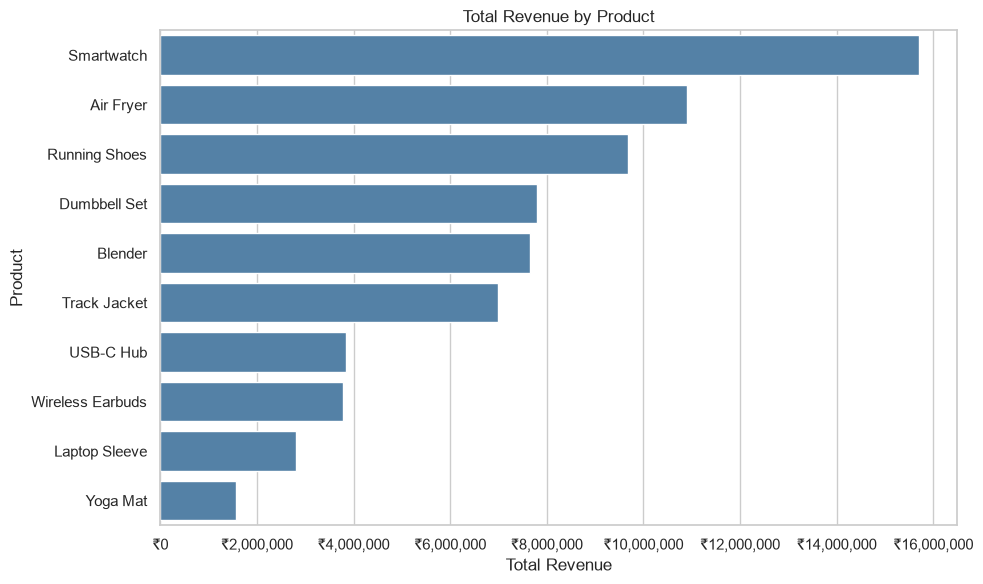

In [3]:
# --- 1a. STATIC chart ---
# Group revenue by product, sort from highest to lowest, and display a static chart.
revenue_by_product = (
    sales_df.groupby("product", as_index=False)["revenue"]
    .sum()
    .sort_values("revenue", ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=revenue_by_product,
    x="revenue",
    y="product",
    color="steelblue",
    ax=ax
)
ax.set_title("Total Revenue by Product")
ax.set_xlabel("Total Revenue")
ax.set_ylabel("Product")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"₹{value:,.0f}"))
plt.tight_layout()
plt.show()


In [4]:
# --- 1b. INTERACTIVE chart ---
# Keep category in the grouped data so it can be displayed on hover.
revenue_by_product_category = (
    sales_df.groupby(["product", "category"], as_index=False)["revenue"]
    .sum()
    .sort_values("revenue", ascending=False)
)

fig = px.bar(
    revenue_by_product_category,
    x="revenue",
    y="product",
    color="category",
    orientation="h",
    hover_data={"category": True, "revenue": ":,.0f"},
    title="Interactive Total Revenue by Product"
)
fig.update_layout(
    xaxis_title="Total Revenue",
    yaxis_title="Product",
    yaxis={"categoryorder": "total ascending"},
    xaxis_tickprefix="₹",
    xaxis_tickformat=",.0f"
)
fig.show()


**Your 1-2 sentence answer:**

The static chart gives a quick comparison of total revenue by product, but it cannot show exact values on demand. The interactive Plotly chart is more useful for exploration because managers can hover over a bar to see its revenue and category without cluttering the chart with labels.


## Task 2 — Dynamic Queries: Let Managers Filter Without Asking You

**Real-world usage:** Regional managers want to self-serve answer questions like *"which
products, in what price range, sold above X units last month?"* without emailing the analytics team
every time (Complaint #1 again, but for filtering rather than just reading).

**Why this technique:** Dynamic queries (double-ended range sliders) let the pattern emerge from the
noise live, with the response updating in real time (Slide 23).

### Your task
Build **two** linked `ipywidgets` range sliders:
- `price_slider` — filters on `unit_price`
- `units_slider` — filters on `units_sold`

Write a function `dynamic_filter(price_range, units_range)` that:
1. Filters `sales_df` to rows where `unit_price` is inside `price_range` **and** `units_sold` is
   inside `units_range`.
2. Prints how many rows match out of the total.
3. Shows a scatter plot of `unit_price` vs `units_sold`, with matching rows highlighted in a
   distinct color against all other rows in gray (same pattern as the Demo notebook's dynamic query
   cell — but you must build the filter condition and the plot yourself for these two columns).

Wire it up with `interact()`.


In [5]:
# Dynamic queries: both sliders filter the same rows by unit price and units sold.
price_slider = widgets.FloatRangeSlider(
    value=(float(sales_df["unit_price"].min()), float(sales_df["unit_price"].max())),
    min=float(sales_df["unit_price"].min()),
    max=float(sales_df["unit_price"].max()),
    step=100,
    description="Unit price:",
    continuous_update=False,
    readout_format=".0f",
    layout=widgets.Layout(width="600px")
)

units_slider = widgets.IntRangeSlider(
    value=(int(sales_df["units_sold"].min()), int(sales_df["units_sold"].max())),
    min=int(sales_df["units_sold"].min()),
    max=int(sales_df["units_sold"].max()),
    step=1,
    description="Units sold:",
    continuous_update=False,
    layout=widgets.Layout(width="600px")
)

def dynamic_filter(price_range, units_range):
    filtered = sales_df[
        sales_df["unit_price"].between(price_range[0], price_range[1])
        & sales_df["units_sold"].between(units_range[0], units_range[1])
    ].copy()

    print(f"{len(filtered):,} / {len(sales_df):,} rows match")

    # Context: all observations in gray. Focus: observations matching both sliders.
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.scatter(
        sales_df["unit_price"], sales_df["units_sold"],
        color="lightgray", alpha=0.35, s=18, label="All rows"
    )
    ax.scatter(
        filtered["unit_price"], filtered["units_sold"],
        color="darkorange", alpha=0.75, s=25, label="Filtered rows"
    )
    ax.set_title("Dynamic Query: Unit Price vs Units Sold")
    ax.set_xlabel("Unit price (₹)")
    ax.set_ylabel("Units sold")
    ax.legend()
    plt.tight_layout()
    plt.show()

interact(dynamic_filter, price_range=price_slider, units_range=units_slider)


interactive(children=(FloatRangeSlider(value=(799.0, 4999.0), continuous_update=False, description='Unit price…

<function __main__.dynamic_filter(price_range, units_range)>

**Your answer:**

Two sliders would not be enough for a dataset that is 50 times larger, especially if it grows beyond the lecture's approximate 100,000-point range. I would use **aggregation or pre-filtering** (for example, summarising sales by store, product, and month before visualising) so the dashboard works with fewer points; server-side querying would also help when users need detailed records.


## Task 3 — Coordinated Views & Cross-View Brushing: Compare Stores Without Flipping Pages

**Real-world usage:** Complaint #2 — "comparing stores means flipping between many PDF pages."
A manager wants to click one store in an overview chart and instantly see that store's category
breakdown and its monthly trend, without losing sight of how it compares to the others.

**Why this technique:** Coordinated multiple views + brushing (Slide 24) — selecting a subset in one
view highlights the same records everywhere else, replacing the working-memory cost of flipping pages.

### Your task
Build **three linked views** for a store the user selects from a dropdown:
1. **Overview bar chart** — total revenue per store (all 6 stores), with the selected store's bar in
   a distinct color and every other store's bar in gray (this is the "muted unselected categories"
   trick from the slide).
2. **Category breakdown** — a pie or bar chart of revenue by `category`, filtered to the selected
   store only.
3. **Monthly trend line** — revenue by `month`, filtered to the selected store only.

Wrap all three in one function driven by a single `ipywidgets.Dropdown` of `store_id` values, and lay
the three charts out together (e.g. with `plt.subplots` for 1+2+3, or separate `display()` calls).


In [6]:
store_overview = sales_df.groupby("store_id", as_index=False)["revenue"].sum()

def store_coordinated_view(selected_store):
    # View 1: overview/context — all stores, with the selected store highlighted.
    colors = [
        "darkorange" if store_id == selected_store else "lightgray"
        for store_id in store_overview["store_id"]
    ]
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))

    axes[0].bar(store_overview["store_id"], store_overview["revenue"], color=colors)
    axes[0].set_title("Context: Revenue Across All Stores")
    axes[0].set_xlabel("Store")
    axes[0].set_ylabel("Total revenue (₹)")

    # View 2: focus — category contribution for the selected store.
    selected_data = sales_df[sales_df["store_id"] == selected_store]
    category_breakdown = selected_data.groupby("category")["revenue"].sum().sort_values(ascending=False)
    axes[1].bar(category_breakdown.index, category_breakdown.values, color="teal")
    axes[1].set_title(f"Focus: Category Revenue — {selected_store}")
    axes[1].set_xlabel("Category")
    axes[1].set_ylabel("Revenue (₹)")
    axes[1].tick_params(axis="x", rotation=30)

    # View 3: focus over time — monthly revenue for the selected store.
    monthly = selected_data.groupby("month", as_index=False)["revenue"].sum()
    axes[2].plot(monthly["month"], monthly["revenue"], marker="o", color="purple")
    axes[2].set_title(f"Monthly Revenue — {selected_store}")
    axes[2].set_xlabel("Month")
    axes[2].set_ylabel("Revenue (₹)")
    axes[2].tick_params(axis="x", rotation=45)

    fig.suptitle(f"Coordinated Store Views: {selected_store}", fontsize=14)
    plt.tight_layout()
    plt.show()

store_selector = widgets.Dropdown(
    options=stores["store_id"].tolist(),
    value=stores["store_id"].iloc[0],
    description="Select store:"
)
interact(store_coordinated_view, selected_store=store_selector)


interactive(children=(Dropdown(description='Select store:', options=('S01', 'S02', 'S03', 'S04', 'S05', 'S06')…

<function __main__.store_coordinated_view(selected_store)>

**Your answer:**

The all-store revenue chart provides the **context** by showing the overall situation, while the selected store's category breakdown and monthly trend provide the **focus**. Brushing is the interaction that selects an item and links the views; focus–context is the visual design idea of keeping the selected detail understandable alongside its wider context. They are related, but they are not the same thing.


## Task 4 — Focus + Context Drill-Down: Investigate the Dip

**Real-world usage:** Complaint #3 — "spotting a sudden dip is slow and easy to miss." One product at
one store has a real anomaly hidden in `sales_df` (planted in Task 0). A manager needs to find it and
drill in **without losing the overview**, using the *cheapest* interaction tier that still answers the
question (Drill-Down Cost Hierarchy, Slide 17).

### Your task
**Part A — find the anomaly.**
Write code that computes, for every `(store_id, product)` pair, the ratio of the *minimum* month's
`units_sold` to the *median* month's `units_sold` across the 24 months. Sort ascending and show the
top 5 most extreme drops. (Hint: `groupby(["store_id","product"]).units_sold.agg(...)` with a custom
function, or compute `min` and `median` separately and combine.)

**Part B — build the drill-down.**
Using **hover** (cheap tier) on an overview chart of all `(store_id, product)` trend lines, let the
user identify the anomalous line. Then, given the `store_id`/`product` you found in Part A, plot its
monthly trend **alongside** a faint gray context line showing the *average* trend across all
stores/products for the same product — so the dip is visible with its context still present (not a
full window replacement).


In [7]:
# --- Part A: find the anomaly ---
# Compare each store-product combination's minimum monthly units with its median.
anomaly_ranking = (
    sales_df.groupby(["store_id", "product"])["units_sold"]
    .agg(min_units="min", median_units="median")
    .reset_index()
)
anomaly_ranking["min_median_ratio"] = (
    anomaly_ranking["min_units"] / anomaly_ranking["median_units"].replace(0, np.nan)
)
anomaly_ranking = anomaly_ranking.sort_values("min_median_ratio", ascending=True)
display(anomaly_ranking.head(5))


,store_id,product,min_units,median_units,min_median_ratio
25,S03,Smartwatch,3.9,21.0,0.185714
47,S05,USB-C Hub,2.0,8.0,0.250000
6,S01,Track Jacket,3.0,10.0,0.300000
27,S03,USB-C Hub,5.0,16.5,0.303030
19,S02,Yoga Mat,3.0,9.5,0.315789


In [8]:
# --- Part B: drill-down with context preserved ---
# Overview: one line for every store-product combination, with identifying hover information.
overview = (
    sales_df.groupby(["month", "store_id", "product"], as_index=False)["units_sold"]
    .sum()
)
overview["series"] = overview["store_id"] + " — " + overview["product"]

overview_fig = px.line(
    overview,
    x="month",
    y="units_sold",
    color="series",
    hover_data=["store_id", "product"],
    title="Overview: Monthly Units Sold by Store and Product"
)
overview_fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Units sold",
    legend_title="Store — Product"
)
overview_fig.show()

# Focus: top-ranked store-product pair; Context: same product's average in all other stores.
top_anomaly = anomaly_ranking.iloc[0]
focus_store = top_anomaly["store_id"]
focus_product = top_anomaly["product"]

focus = sales_df[
    (sales_df["store_id"] == focus_store)
    & (sales_df["product"] == focus_product)
].groupby("month", as_index=False)["units_sold"].sum()
focus["view"] = f"Focus: {focus_store} — {focus_product}"

context = sales_df[
    (sales_df["product"] == focus_product)
    & (sales_df["store_id"] != focus_store)
].groupby("month", as_index=False)["units_sold"].mean()
context["view"] = f"Context: Other stores' average — {focus_product}"

comparison = pd.concat([focus, context], ignore_index=True)
drill_fig = px.line(
    comparison,
    x="month",
    y="units_sold",
    color="view",
    markers=True,
    title=f"Drill-down: {focus_product} at {focus_store} vs Other Stores"
)
drill_fig.update_layout(
    xaxis_title="Month",
    yaxis_title="Units sold",
    legend_title="Focus and context"
)
drill_fig.show()

print(f"Top anomaly selected: {focus_store} — {focus_product} (minimum/median ratio: {top_anomaly['min_median_ratio']:.3f})")


Top anomaly selected: S03 — Smartwatch (minimum/median ratio: 0.186)


**Your answer:**

I first spotted the anomaly by scanning the sorted min/median-ratio ranking, which mainly uses **eye fixation**. I then investigated it in the focused monthly trend alongside the average for other stores, which is a drill-down to a more detailed view (similar to **window replacement**). Using a cheap scan to detect a problem and a more detailed view to investigate it is appropriate because not every observation needs an expensive interaction.


## Task 5 — Table Lens: A Scannable Product Performance Table

**Real-world usage:** A manager wants a single table listing every product's total revenue, total
profit, and average rating across all stores — but a plain spreadsheet of 10 rows x many numeric
columns is still hard to compare at a glance across all three metrics simultaneously.

**Why this technique:** Table Lens (Slide 27) maps numeric columns to in-cell bars, so magnitude
differences are visible pre-attentively while the table stays sortable/readable as text.

### Your task
1. Build a summary DataFrame: one row per `product`, columns for total `revenue`, total `profit`, and
   mean `avg_rating`.
2. Sort it by total revenue, descending.
3. Style it as a Table Lens using `.style.bar(...)` — a different bar color per numeric column, as in
   the Demo notebook — and add a meaningful `.set_caption(...)`.
4. Below the table, add **one more cell**: sort the *same* summary table by `profit` instead of
   `revenue`, and re-render the styled table. Do the top rows change order? Note what that tells a
   manager about revenue vs. profitability.


In [9]:
# Product-level summary: revenue and profit are totals; rating is the mean.
product_summary = (
    sales_df.groupby("product", as_index=False)
    .agg(
        revenue=("revenue", "sum"),
        profit=("profit", "sum"),
        avg_rating=("avg_rating", "mean")
    )
    .sort_values("revenue", ascending=False)
)

revenue_sorted_table = (
    product_summary.style
    .bar(subset=["revenue"], color="#5B9BD5")
    .bar(subset=["profit"], color="#70AD47")
    .bar(subset=["avg_rating"], color="#ED7D31", vmin=0, vmax=5)
    .format({"revenue": "₹{:,.0f}", "profit": "₹{:,.0f}", "avg_rating": "{:.2f}"})
    .set_caption("Product Performance — Sorted by Total Revenue")
)
display(revenue_sorted_table)


,product,revenue,profit,avg_rating
5,Smartwatch,"₹15,706,358","₹3,881,507",4.09
0,Air Fryer,"₹10,901,274","₹2,593,731",4.04
4,Running Shoes,"₹9,688,731","₹2,303,075",4.10
2,Dumbbell Set,"₹7,796,880","₹1,829,127",4.11
1,Blender,"₹7,648,773","₹1,860,309",4.04
6,Track Jacket,"₹6,992,502","₹1,610,283",4.13
7,USB-C Hub,"₹3,842,442","₹907,435",4.09
8,Wireless Earbuds,"₹3,769,985","₹890,554",4.09
3,Laptop Sleeve,"₹2,801,284","₹664,358",4.08
9,Yoga Mat,"₹1,560,447","₹370,892",4.07


In [10]:
# Re-sort the same summary by profit to compare commercial performance.
profit_sorted = product_summary.sort_values("profit", ascending=False)

profit_sorted_table = (
    profit_sorted.style
    .bar(subset=["revenue"], color="#5B9BD5")
    .bar(subset=["profit"], color="#70AD47")
    .bar(subset=["avg_rating"], color="#ED7D31", vmin=0, vmax=5)
    .format({"revenue": "₹{:,.0f}", "profit": "₹{:,.0f}", "avg_rating": "{:.2f}"})
    .set_caption("Product Performance — Sorted by Total Profit")
)
display(profit_sorted_table)


,product,revenue,profit,avg_rating
5,Smartwatch,"₹15,706,358","₹3,881,507",4.09
0,Air Fryer,"₹10,901,274","₹2,593,731",4.04
4,Running Shoes,"₹9,688,731","₹2,303,075",4.10
1,Blender,"₹7,648,773","₹1,860,309",4.04
2,Dumbbell Set,"₹7,796,880","₹1,829,127",4.11
6,Track Jacket,"₹6,992,502","₹1,610,283",4.13
7,USB-C Hub,"₹3,842,442","₹907,435",4.09
8,Wireless Earbuds,"₹3,769,985","₹890,554",4.09
3,Laptop Sleeve,"₹2,801,284","₹664,358",4.08
9,Yoga Mat,"₹1,560,447","₹370,892",4.07


**Your observation:**

The revenue-sorted table ranks products by the amount of money generated, while the profit-sorted table ranks them by the money retained after costs. The top products can therefore differ: a product may generate high revenue but have a lower profit margin, while another product with lower revenue may contribute more profit. Ratings provide a separate view of customer satisfaction and should not be confused with financial performance.


## Task 6 — Assemble a Single-Screen Monitoring Dashboard (open-ended)

**Real-world usage:** All three complaints at once. UrbanCart wants a **single screen** a regional
manager can glance at every morning — no interaction required to read the headline state, per the
Dashboard Patterns slide (Slide 28): critical indicators visible at a glance, with a peripheral-tier
alert that uses color (not subtlety) to flag something that needs attention.

### Your task
Build a 2x2 dashboard (`plt.subplots(2, 2, ...)`) with:

1. **Top-left — KPI summary panel** (`ax.axis("off")` + `ax.text(...)`): total revenue, total profit,
   overall average rating, and number of active stores, computed from `sales_df`.
2. **Top-right — mid-term analysis panel**: revenue by `region` (bar chart).
3. **Bottom-left — long-term trend panel**: total revenue by `month`, across all stores (line chart).
4. **Bottom-right — peripheral alert panel**: check whether **any** `(store_id, product)` pair has a
   month where `units_sold` fell below **25% of its own median** for that pair (this is the anomaly
   you found in Task 4, but write the check generically so it would catch *any* such case, not just
   the one you already know about). Show a red "ALERT — N issue(s) found" indicator if any exist, or
   a green "OK" indicator if not.

This task is intentionally the least scaffolded — you decide the exact `groupby` calls, panel layout
details, and styling. Reuse patterns from Tasks 1-5 and the Demo notebook where they fit, but write
the logic yourself.


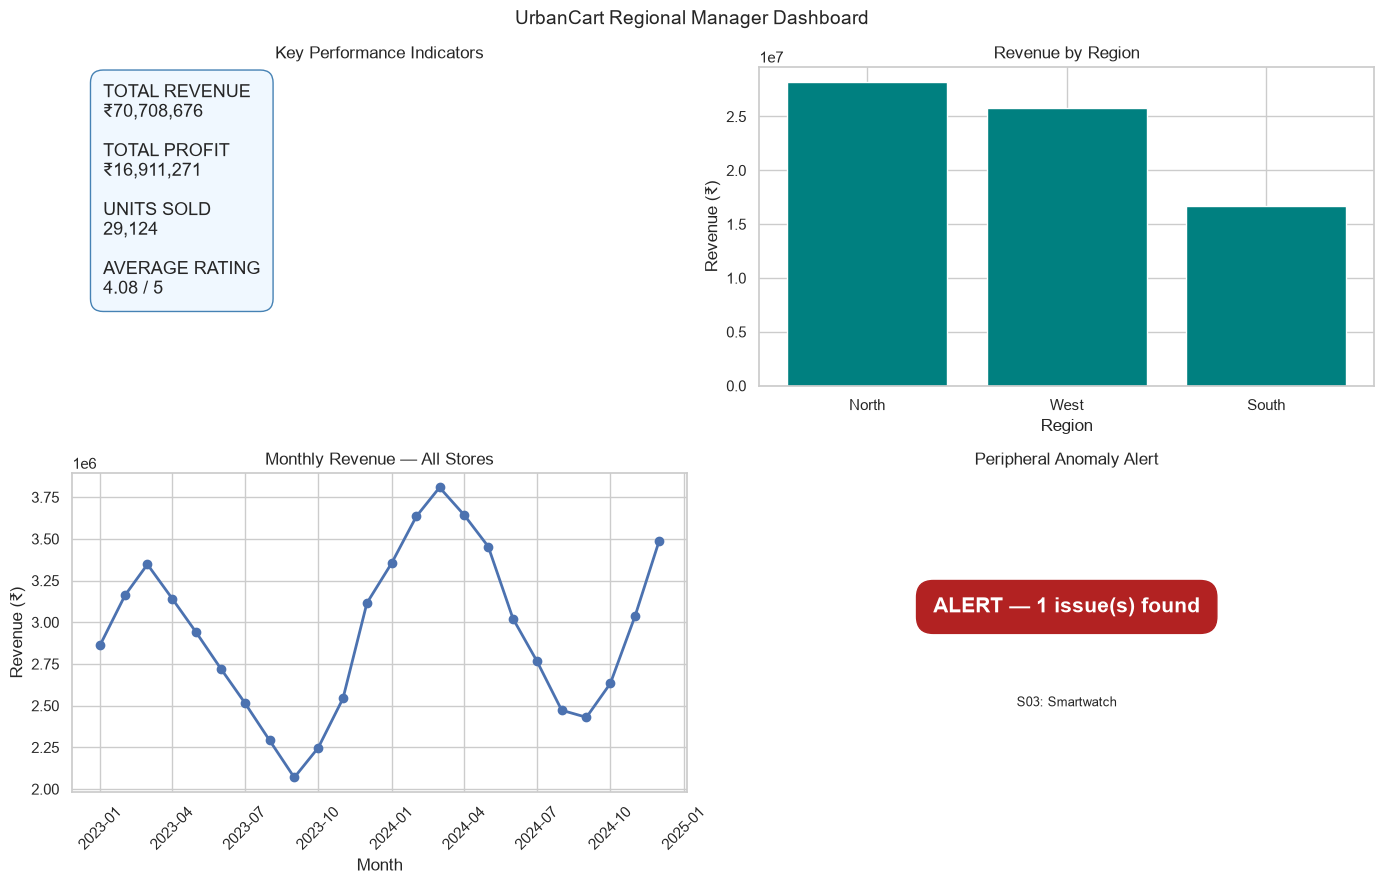

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# --- Panel 1: KPI summary (top-left) ---
total_revenue = sales_df["revenue"].sum()
total_profit = sales_df["profit"].sum()
total_units = sales_df["units_sold"].sum()
average_rating = sales_df["avg_rating"].mean()

axes[0, 0].axis("off")
kpi_text = (
    f"TOTAL REVENUE\n₹{total_revenue:,.0f}\n\n"
    f"TOTAL PROFIT\n₹{total_profit:,.0f}\n\n"
    f"UNITS SOLD\n{total_units:,.0f}\n\n"
    f"AVERAGE RATING\n{average_rating:.2f} / 5"
)
axes[0, 0].text(
    0.05, 0.95, kpi_text, va="top", ha="left", fontsize=13,
    bbox=dict(boxstyle="round,pad=0.7", facecolor="aliceblue", edgecolor="steelblue")
)
axes[0, 0].set_title("Key Performance Indicators")

# --- Panel 2: revenue by region (top-right) ---
region_revenue = sales_df.groupby("region")["revenue"].sum().sort_values(ascending=False)
axes[0, 1].bar(region_revenue.index, region_revenue.values, color="teal")
axes[0, 1].set_title("Revenue by Region")
axes[0, 1].set_xlabel("Region")
axes[0, 1].set_ylabel("Revenue (₹)")

# --- Panel 3: total revenue by month, all stores (bottom-left) ---
monthly_revenue = sales_df.groupby("month")["revenue"].sum().sort_index()
axes[1, 0].plot(monthly_revenue.index, monthly_revenue.values, marker="o", linewidth=2)
axes[1, 0].set_title("Monthly Revenue — All Stores")
axes[1, 0].set_xlabel("Month")
axes[1, 0].set_ylabel("Revenue (₹)")
axes[1, 0].tick_params(axis="x", rotation=45)

# --- Panel 4: peripheral alert panel (bottom-right) ---
pair_stats = sales_df.groupby(["store_id", "product"])["units_sold"].transform("median")
alert_rows = sales_df[sales_df["units_sold"] < 0.25 * pair_stats]
alert_pairs = alert_rows[["store_id", "product"]].drop_duplicates()
alert_count = len(alert_pairs)

axes[1, 1].axis("off")
if alert_count:
    alert_message = f"ALERT — {alert_count} issue(s) found"
    alert_color = "firebrick"
else:
    alert_message = "OK — No unusual dips detected"
    alert_color = "darkgreen"
axes[1, 1].text(
    0.5, 0.58, alert_message, ha="center", va="center",
    fontsize=15, fontweight="bold", color="white",
    bbox=dict(boxstyle="round,pad=0.8", facecolor=alert_color, edgecolor=alert_color)
)
if alert_count:
    alert_list = "\n".join(
        f"{row.store_id}: {row.product}" for row in alert_pairs.itertuples(index=False)
    )
    axes[1, 1].text(0.5, 0.28, alert_list, ha="center", va="center", fontsize=9)
axes[1, 1].set_title("Peripheral Anomaly Alert")

fig.suptitle("UrbanCart Regional Manager Dashboard", fontsize=14)
plt.tight_layout()
plt.show()


## Reflection

1. **The biggest time saving** comes from coordinated views and brushing because a manager can select a store and immediately see its category breakdown and monthly trend without searching through separate reports.

2. **The hardest technique** was focus–context drill-down because the detailed view must make the unusual behaviour clear without hiding the comparison with other stores. The main trade-off is between showing enough context and keeping the focused information readable.

3. I would add a **geometric fisheye view** to a very large store-by-product performance table. It could enlarge the rows or products a manager is investigating while keeping the surrounding rows visible for context, reducing the need to repeatedly switch between a detailed view and the full list.